**Group information**

| Family name | First name | Email address |
| ----------- | ---------- | ------------- |
|             |            |               |
|             |            |               |
|             |            |               |

# Language - Solutions

This tutorial examines the use of deep language models to predict the political affiliation of tweet authors, either Republican or Democrat. Using a labelled [dataset](https://www.kaggle.com/datasets/kapastor/democratvsrepublicantweets?resource=download) of approximately 75,000 tweets of varying lengths, the goal is to learn a function that maps textual input to the probability that a given tweet is authored by a Democrat. The modelling approach should explicitly capture both the semantic and syntactic structure of the language.

**Large language models** can be powerful learning tools, but make sure to continue asking questions until you fully understand the produced answer and can judge its correctness. Simply copy-pasting generated code does not contribute to learning and is a waste of your class time.

In [32]:
# On Google Colab
!pip install captum torchinfo

In [33]:
# Packages
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import re
import shutil
import torch
import torchinfo
import tqdm
import umap

from sklearn import metrics, model_selection
from torch import nn, optim, utils
from urllib import request
tqdm.tqdm.pandas()

# Device
device = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
device = torch.device(device)

In [34]:
# Utilities
def download_data():
    if os.getcwd().endswith('/data'):
        print('Data folder already exists')
    else:
        request.urlretrieve('https://www.dropbox.com/scl/fo/tlell6unso4rnvivkcw6a/ALTZR3P_63V4DrfcrsNjq-k?rlkey=thaxsewr1k1b1u15z0cc6ogog&dl=1', 'data.zip')
        shutil.unpack_archive('data.zip', 'data')
        os.remove('data.zip')
        os.chdir('data')

In [35]:
# Execute on first run
# download_data()
os.chdir(f"{os.path.expanduser('~')}/Library/CloudStorage/Dropbox/teaching/text_analysis/3_learned/learned_practice/tweets_data")

**1. Descriptive statistics**

Load the `dataset.csv` file and display a subset of tweets with their associated party labels. Then calculate the label frequency distribution. Finally, use regular expressions to extract and report the most frequent hashtags (`#`) and user mentions (`@`) in the dataset.

In [36]:
# Loads dataset
dataset = pd.read_csv('dataset.csv', index_col='tweet_id')

# Prints a sample of texts and labels
for _, row in dataset.sample(3).iterrows():
    print(f'TWEET: {row.tweet}\nPARTY: {row.party}\n')

# Displays labels frequencies
print('FREQUENCIES:', dataset.party.value_counts(), sep='\n')

TWEET: It was a pleasure to address the @nafoalliance this morning. Forestry is a driving force in #ar4 and forest owners... 
PARTY: republican

TWEET: On Friday, we're holding our 94th town hall. Hope you can join us for another great conversation. Click here for co... 
PARTY: democrat

TWEET: RT @nature_ohio: Grateful to @RepMarciaFudge  for introducing important legislation to help farmers adopt soil health &amp; water quality manag...
PARTY: democrat

FREQUENCIES:
party
democrat      37500
republican    37500
Name: count, dtype: int64


In [37]:
# Top hashtags and mentions
hashtags = dataset['tweet'].str.findall(r'(#\w+)').explode().value_counts()
mentions = dataset['tweet'].str.findall(r'(@\w+)').explode().value_counts()

print(f'\nTOP HASHTAGS:\n{hashtags.head()}')
print(f'\nTOP MENTIONS:\n{mentions.head()}')


TOP HASHTAGS:
tweet
#GOPTaxScam           596
#TaxReform            473
#TaxCutsandJobsAct    456
#SOTU                 316
#DACA                 309
Name: count, dtype: int64

TOP MENTIONS:
tweet
@realDonaldTrump    1138
@POTUS              1075
@HouseGOP            923
@SpeakerRyan         733
@HouseCommerce       396
Name: count, dtype: int64


**2. Tokenize**

In this exercise, we aim to align our word tokens with the precomputed GloVe embeddings, so the tokenization process should maximise the quality of these matches. We therefore retain only lowercase alphabetic tokens and exclude words that are part of hashtags or mentions, as these cannot be matched. Finally, we discard tokens that occur fewer than 5 times in the dataset.


In [38]:
dataset['tokens'] = dataset['tweet'].progress_apply(lambda tweet: re.findall(r'(?<![#@])\b[a-z]+\b', tweet.lower()))
rare_tokens = dataset['tokens'].explode().value_counts()
rare_tokens = set(rare_tokens.loc[lambda x: x < 5].index)
dataset['tokens'] = dataset['tokens'].progress_apply(lambda tokens: [token for token in tokens if token not in rare_tokens])

100%|██████████| 75000/75000 [00:00<00:00, 1184363.25it/s]


**3. Match embeddings**

Load the pre-trained GloVe embeddings from `glove_embeddings.csv`, using `token` as the index column. Construct the vocabulary as the set of unique tokens. Compute and report the embedding match rate, and provide examples of both matched and unmatched tokens. Observe the first two tokens ; what are their role?

Note: For efficiency, I retained only the subset of embeddings corresponding to tokens in the vocabulary from the full 27B-token dictionary.

In [ ]:
# Loads embeddings
embeds = pd.read_csv('glove_embeddings.csv', index_col='token')

# Intialises mappings (for later)
stoi = {token: i for i, token in enumerate(embeds.index)} # string to index
itos = {i: token for i, token in enumerate(embeds.index)} # index to string

# Checks matching
vocab     = sorted(set(dataset['tokens'].explode()))
matched   = [token for token in vocab if token in embeds.index]
unmatched = [token for token in vocab if token not in embeds.index]

# Checks matching
print(f'\nMATCH RATE: {len(matched)/len(vocab):.2%}')

print('\nMATCHED TOKENS:')
for t in np.random.choice(matched, 5, replace=False):
    print(f'- {t}')

print('\nUNMATCHED TOKENS:')
for t in np.random.choice(unmatched, 5, replace=False):
    print(f'- {t}')

del vocab, matched, unmatched


MATCH RATE: 98.06%

MATCHED TOKENS:
- barbara
- giants
- centered
- pill
- nonviolent

UNMATCHED TOKENS:
- pleasants
- kaptur
- amendmen
- pasquotank
- anwr


**4. Data loaders**

Map each tokenised tweet to its corresponding vocabulary indices. Encode party labels as `0.0` (Republican) and `1.0` (Democrat). Split the dataset into training (80%) and test (20%) sets. Using the provided `TweetDataset` and `collate_fn`, initialise `utils.data.DataLoader` instances for both splits with `batch_size=128`, enabling shuffling for the training loader.

In [40]:
class TweetDataset(torch.utils.data.Dataset):
    
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def collate_fn(batch, pad_index:int=0):
    X, y = zip(*batch)
    X = [torch.tensor(x, dtype=torch.long) for x in X]
    X = nn.utils.rnn.pad_sequence(X, batch_first=True, padding_value=pad_index)
    y = torch.tensor(y, dtype=torch.float)
    return X, y

In [41]:
# Formats data
dataset['X'] = dataset['tokens'].progress_apply(lambda tokens: [stoi.get(token, stoi['<unk>']) for token in tokens])
dataset['Y'] = (dataset['party'] == 'democrat')
dataset['sample'] = np.random.choice(a=['train', 'val', 'test'], size=len(dataset), p=[0.7, 0.15, 0.15])

100%|██████████| 75000/75000 [00:00<00:00, 289038.82it/s]


In [42]:
# Initialises datasets and dataloaders
train_dataset = TweetDataset(dataset.loc[dataset['sample'] == 'train', 'X'].values, dataset.loc[dataset['sample'] == 'train', 'Y'].values)
val_dataset   = TweetDataset(dataset.loc[dataset['sample'] == 'val',   'X'].values, dataset.loc[dataset['sample'] == 'val',   'Y'].values)
test_dataset  = TweetDataset(dataset.loc[dataset['sample'] == 'test',  'X'].values, dataset.loc[dataset['sample'] == 'test',  'Y'].values)
train_loader  = utils.data.DataLoader(dataset=train_dataset, batch_size=128, shuffle=True,  collate_fn=collate_fn)
val_loader    = utils.data.DataLoader(dataset=val_dataset,   batch_size=128, shuffle=False, collate_fn=collate_fn)
test_loader   = utils.data.DataLoader(dataset=test_dataset,  batch_size=128, shuffle=False, collate_fn=collate_fn)

''' Checks a batch
X, y = next(iter(train_loader))
print(f'X: {X.shape}\nY: {y.shape}')
del X, y
'''

" Checks a batch\nX, y = next(iter(train_loader))\nprint(f'X: {X.shape}\nY: {y.shape}')\ndel X, y\n"

**5. Model structure**

Create an embedding layer that maps token indices to embedding vectors using `torch.nn.Embedding.from_pretrained`, with `freeze=True` to keep the embeddings fixed during training.

Define a PyTorch model class that maps a token sequence of shape $b \times t \times d$ to a scalar score using an embedding layer, a 32-unit bidirectional RNN or LSTM encoder, dropout regularisation, and a single-unit output layer with no activation. For numerical stability, PyTorch loss functions expect raw logit scores rather than a probability. The sigmoid transformation is applied internally within the loss function. 

Instantiate the model with a dropout probability of $0.5$, as these models quickly overfit, and print its structure using `torchinfo.summary`.

In [ ]:
# Embedding layer
embedding_layer = torch.nn.Embedding.from_pretrained(
    embeddings=torch.tensor(embeds.values, dtype=torch.float32),
    freeze=True, # Embeddings are not updated during training
    padding_idx=stoi['<pad>']
)

# Model structure
class LSTMModel(torch.nn.Module):
    def __init__(self, embedding_layer:torch.nn.Embedding, hidden_dim:int, dropout:float=0.0) -> None:
        super().__init__()
        self.embedding = embedding_layer
        self.encoder   = torch.nn.LSTM(input_size=embedding_layer.embedding_dim, hidden_size=hidden_dim, num_layers=1, bidirectional=True, batch_first=True)
        self.dropout   = torch.nn.Dropout(dropout)
        self.output    = torch.nn.Linear(hidden_dim * 2, 1)

    def forward(self, x:torch.Tensor, return_hidden=False) -> torch.Tensor:
        ew = self.embedding(x)
        _, (ed, _) = self.encoder(ew)
        ed = torch.cat((ed[0], ed[1]), dim=1)
        ed = self.dropout(ed)
        s  = self.output(ed)
        if return_hidden:
            return ed, s
        else:
            return s

# Instantiates model
model = LSTMModel(embedding_layer=embedding_layer, hidden_dim=32, dropout=0.5)
print(torchinfo.summary(model, input_data=torch.zeros((1, 10), dtype=torch.long)))

Layer (type:depth-idx)                   Output Shape              Param #
LSTMModel                                [1, 1]                    --
├─Embedding: 1-1                         [1, 10, 100]              (1,069,500)
├─LSTM: 1-2                              [1, 10, 64]               34,304
├─Dropout: 1-3                           [1, 64]                   --
├─Linear: 1-4                            [1, 1]                    65
Total params: 1,103,869
Trainable params: 34,369
Non-trainable params: 1,069,500
Total mult-adds (Units.MEGABYTES): 1.41
Input size (MB): 0.00
Forward/backward pass size (MB): 0.01
Params size (MB): 4.42
Estimated Total Size (MB): 4.43


**6. Model training** 

Define the appropriate loss function `nn.BCEWithLogitsLoss` and an optimisation algorithm (e.g. `optim.AdamW`).  Write a PyTorch training loop to estimate the model parameters using the training sample, with a maximum of 10 epochs and a learning rate of `1e-3`. Remember to move the model and the batch data to the correct device.

Optionally, implement an early-stopping procedure on the validation sample to monitor generalisation performance across epochs, stop training when overfitting begins, and restore the parameters that perform best out of sample.

In [44]:
# Define loss and optimiser
model     = model.to(device)
criterion = nn.BCEWithLogitsLoss(reduction='mean')
optimiser = optim.AdamW(model.parameters(), lr=1e-3)

In [45]:
class EarlyStopping:
    
    def __init__(self, patience=3, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best = float('inf')
        self.count = 0
        self.best_state = None

    def step(self, val_loss, model):
        if val_loss < self.best - self.min_delta:
            self.best = val_loss
            self.count = 0
            self.best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            return False
        else:
            self.count += 1
            return self.count >= self.patience
        
early_stopping = EarlyStopping(patience=5, min_delta=1e-4)

In [ ]:
n_epochs = 25
for epoch in range(n_epochs):

    # Training
    model.train()
    train_obs, train_loss = 0, 0
    progress = tqdm.tqdm(train_loader, desc=f'Epoch {epoch+1:02d}/{n_epochs}', unit='batch')
    for x, y in progress:
        x, y = x.to(device), y.to(device)
        optimiser.zero_grad()
        s    = model(x)
        loss = criterion(s.squeeze(), y)
        loss.backward()
        optimiser.step()
        train_obs  += x.size(0)
        train_loss += loss.item() * x.size(0)
        progress.set_postfix(train_loss=f'{train_loss / train_obs:.4f}')

    # Validation
    model.eval()
    val_obs, val_loss = 0, 0
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            s    = model(x)
            loss = criterion(s.squeeze(), y)
            val_obs  += x.size(0)
            val_loss += loss.item() * x.size(0)
    
    # Early stopping
    if early_stopping.step(val_loss / val_obs, model):
        print(f'Early stopping at epoch {epoch+1}')
        break

# Restores best model and saves
model.load_state_dict(early_stopping.best_state)
torch.save(model.state_dict(), 'tweet_model.pth')

Epoch 01/25:  73%|███████▎  | 302/411 [00:02<00:00, 121.37batch/s, train_loss=0.6730]

**7. Threshold selection**

Write a prediction loop for the validation sample and, using the predicted probabilities, select the ROC-based decision threshold that maximises the true positive rate while minimising the false positive rate. Given the class balance in the training sample, what threshold value would you expect?

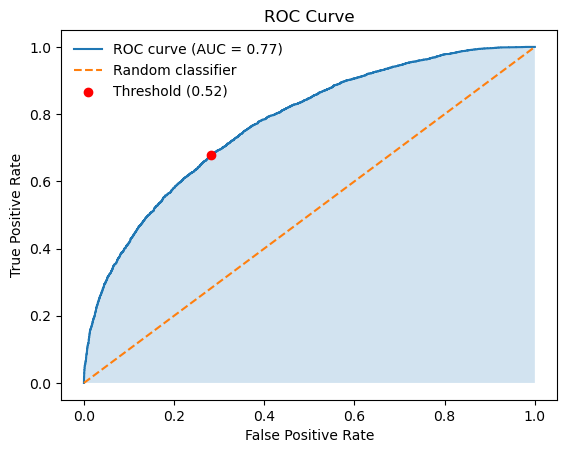

In [ ]:
# Loads the parameters of the pre-trained model
model.load_state_dict(torch.load('tweet_model.pth', weights_only=False))
model.to(device)

# Validation loop
model.eval()
P_val, Y_val = [], []
with torch.no_grad():
    for x, y in val_loader:
        s = model(x.to(device))
        P_val.append(torch.sigmoid(s.squeeze()))
        Y_val.append(y)

P_val = torch.cat(P_val).detach().cpu()
Y_val = torch.cat(Y_val)

# ROC curve
fpr, tpr, thr = metrics.roc_curve(Y_val, P_val)
joudenJ   = tpr - fpr
threshold = thr[np.argmax(joudenJ)]

# Plots ROC curve
auc = metrics.roc_auc_score(Y_val, P_val)
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc:.2f})')
plt.fill_between(fpr, tpr, alpha=0.2)  # highlight AUC area
plt.plot([0, 1], [0, 1], linestyle='--', label='Random classifier')
plt.scatter(fpr[np.argmax(joudenJ)], tpr[np.argmax(joudenJ)], color='red', label=f'Threshold ({threshold:.2f})', zorder=2)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='upper left', frameon=False)
plt.show()

**8. Model performance** 

Apply the prediction loop to the test sample, use the selected threshold, and evaluate performance with `metrics.classification_report` and `metrics.confusion_matrix`.

              precision    recall  f1-score   support

  republican       0.69      0.74      0.71      5628
    democrat       0.71      0.66      0.69      5558

    accuracy                           0.70     11186
   macro avg       0.70      0.70      0.70     11186
weighted avg       0.70      0.70      0.70     11186



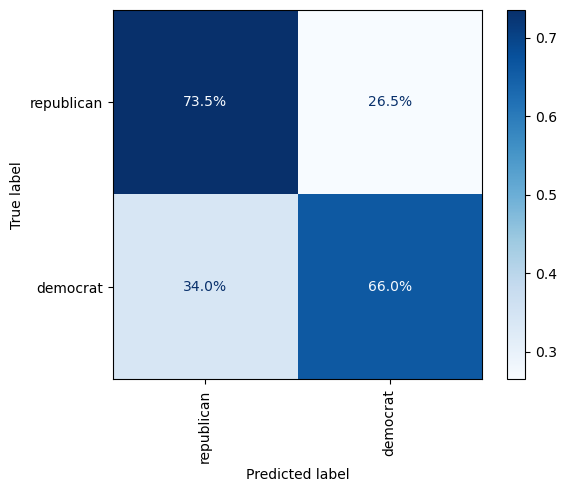

In [ ]:
# Evaluation loop
model.eval()
S_test, Y_test = [], []
with torch.no_grad():
    for x, y in test_loader:
        s = model(x.to(device))
        S_test.append(s.squeeze())
        Y_test.append(y)

P_test = torch.sigmoid(torch.cat(S_test)).detach().cpu()
Y_test = torch.cat(Y_test)

# Applies optimal threshold
Yh_test = (P_test > threshold).long().detach().cpu()

# Classification metrics
print(metrics.classification_report(Y_test, Yh_test, target_names=['republican', 'democrat'], zero_division=0))
metrics.ConfusionMatrixDisplay.from_predictions(Y_test, Yh_test, display_labels=['republican', 'democrat'], normalize='true', values_format='.1%', cmap='Blues', xticks_rotation='vertical')

**9. Prediction**

Display the tweets with the highest and lowest predicted Democrat probability, as well as those with the most neutral scores. Write a pipeline to test the model on your own custom input sentences.

In [ ]:
toptweets = dataset[['tweet']][dataset['sample'] == 'test']
toptweets = toptweets.assign(proba=P_test)
toptweets.sort_values('proba', inplace=True, ascending=False)

print('\nTOP DEMOCRAT TWEETS:')
for tweet in toptweets['tweet'].head():
    print(f'- {tweet}')

print('\nTOP REPUBLICAN TWEETS:')
for tweet in toptweets['tweet'].tail():
    print(f'- {tweet}')

print('\nNEUTRAL TWEETS:')
for tweet in toptweets[toptweets['proba'].between(0.49, 0.51)].sample(5)['tweet']:
    print(f'- {tweet}')


TOP DEMOCRAT TWEETS:
- The #GOPTaxScam gave a trillion dollars to billionaires &amp; massive corporations. Now, Republicans want to gut the Ch... 
- The Trump Administration's new census question about citizenship could lower the response rate, affect accuracy &amp; i... 
- RT @HouseDemWomen: On average, women are paid just 80 cents for every $1 paid to male counterparts. For women of color, the #wagegap is muc...
- RT @BillPascrell: About $1.6 trillion of the #GOPTaxScam law will go right into the pockets of the big corporations and top 1 percent. Can...
- On average, women are paid just 80 cents for every $1 paid to male counterparts. For women of color, the #wagegap i... 

TOP REPUBLICAN TWEETS:
- Major wins for Iowa following the passage of the Tax Cuts &amp; Jobs Act - utility savings, bonuses, pay raises, invest... 
- Good news: tomorrow is the last day you will have to file your taxes under the old and cumbersome tax code. Thanks... 
- In case you missed it over the holidays, h

In [ ]:
# Checks model predictions
def preprocess_tweets(tweets:torch.Tensor, pad_index:int=stoi['<pad>']) -> torch.Tensor:
    X = [re.findall(r'(?<![#@])\b[a-z]+\b', tweet.lower()) for tweet in tweets]
    X = [[stoi.get(token, stoi['<unk>']) for token in tokens] for tokens in X]
    X = [torch.tensor(x, dtype=torch.long) for x in X]
    X = nn.utils.rnn.pad_sequence(X, batch_first=True, padding_value=pad_index)
    return X

tweets = [
    'Lower taxes, strong borders, and American values first!', 
    'Equality, climate action, and healthcare for all!'
    ]

X_pred = preprocess_tweets(tweets)
with torch.no_grad():
    model.eval()
    S_pred = model(X_pred.to(device))

P_pred = torch.sigmoid(S_pred.squeeze()).detach().cpu()

for tweet, proba in zip(tweets, P_pred):
    print(f"x:  {tweet}\nyh: {proba:.2f} ({'democrat' if proba > 0.5 else 'republican'})\n")

x:  Lower taxes, strong borders, and American values first!
yh: 0.32 (republican)

x:  Equality, climate action, and healthcare for all!
yh: 0.87 (democrat)



**10. Sequence representations**

The LSTM layer outputs numerical sequence representations that serve as tweet embeddings.  Extract these embeddings and, for a selected tweet, identify the most similar tweets using cosine similarity. How do these representations compare with those obtained via singular value decomposition? What do you think these distances reflect?

In [ ]:
# Finds closest tweets
def find_closest(source:pd.Series, target:pd.DataFrame) -> pd.Series:
    vector  = np.array(source).reshape(1, -1)
    closest = metrics.pairwise.cosine_similarity(vector, target).flatten()
    closest = pd.Series(closest, index=target.index)
    closest = closest.sort_values(ascending=False)
    return closest

# Evaluation loop
model.eval()
Ed_test = []
with torch.no_grad():
    for x, y in test_loader:
        h, _ = model(x.to(device), return_hidden=True)
        Ed_test.append(h)
Ed_test = torch.cat(Ed_test).detach().cpu()
Ed_test = pd.DataFrame(Ed_test, index=dataset.loc[dataset['sample'] == 'test'].index)

# Finds closest tweets
closest = find_closest(source=Ed_test.sample(1), target=Ed_test)

print(f'CLOSEST TWEETS:')
for tweet in dataset['tweet'].loc[closest.index].head():
    print(f'- {tweet}')

CLOSEST TWEETS:
- Hazard mitigation specialists will be providing free repair and rebuilding advice in Nueces County until the 22nd. 
- RT @RepLukeMesser: Live stream 4 @GOPpolicy hearing on #college completion/affordability is ready to go! Watch:  htt...
- RT @HesperiaPolice: Tonight at Hesperia City Council, several were honored for their continued support &amp; dedication to Hesperia PAL. https:...
- RT @HurdOnTheHill: The final @GOPoversight #IT Subcommittee hearing on #ArtificialIntelligence is #HappeningNow. LIVESTREAM → 
- RT @RepRatcliffe: Tomorrow at 2PM @HurdOnTheHill and I will chair a joint @HouseHomeland &amp; @GOPoversight #cyber subcommittee hearing on @DH...


These sequence embeddings are task-specific, having been optimised for the classification objective. The distances between them may reflect political alignment rather than general semantic or syntactic similarity, as they are derived from the concatenated final hidden states of the bidirectional LSTM that summarise each tweet.

**BONUS (intermediate)** 

Project the tweet representations into a two- or three-dimensional space using a dimensionality-reduction method such as UMAP. Colour points by predicted probability and distinguish correct and incorrect predictions by marker symbol.

In [ ]:
# Packages
import plotly.express as px

# UMAP projection (3D)
UMAP = umap.UMAP(n_components=3, n_neighbors=50, min_dist=0.1)
proj = UMAP.fit_transform(Ed_test)
proj = pd.DataFrame(proj, index=Ed_test.index, columns=['umap1', 'umap2', 'umap3'])
figdata = proj.join(dataset['tweet'])
figdata = figdata.assign(proba=P_test, correct=Y_test == Yh_test)

# Figure
fig = px.scatter_3d(
    figdata,
    x='umap1',
    y='umap2',
    z='umap3',
    color='proba',
    symbol='correct',
    hover_name='tweet',
    title='Document projection in latent space',
    labels={
        'umap1': 'UMAP 1',
        'umap2': 'UMAP 2',
        'umap3': 'UMAP 3',
        'proba': 'Predicted probability'
    },
    color_continuous_scale='Inferno',
    symbol_map={True: 'circle', False: 'circle-open'}
)
fig.update_traces(marker=dict(size=3, line=dict(width=0.1, color='black')))
fig.update_layout(template='plotly_dark')
fig.write_html('tweet_umap_3d.html', include_plotlyjs='cdn')
del UMAP, proj, figdata, fig

/Users/goclem/Software/miniconda3/envs/deeplearning/lib/python3.12/site-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


**BONUS (advanced)** 

Using `captum.attr.LayerIntegratedGradients`, compute token-level importance by averaging attribution scores with respect to the model’s predictions, either for a single instance or across the full dataset. Identify the most influential words, as well as those most predictive of Democratic and Republican classifications.

In [ ]:
# Packages
import captum
from numpy.core.numeric import indices

def feature_importance(loader:torch.utils.data.DataLoader, n_steps:int=25) -> dict:
    model.eval()
    model.to('cpu')
    LIG    = captum.attr.LayerIntegratedGradients(model, model.embedding)
    tokens, scores = [], []
    for inputs, _ in tqdm.tqdm(loader, desc='Computing feature importance'):
        score, _ = LIG.attribute(
            inputs=inputs,
            baselines=torch.full_like(inputs, fill_value=stoi['<pad>']),
            target=0,
            n_steps=n_steps,
            return_convergence_delta=True
        )
        score = score.mean(dim=-1) # Use .abs().mean(dim=-1) for absolute importance
        scores.extend(score)
        tokens.extend(inputs)
    tokens = nn.utils.rnn.pad_sequence(tokens, batch_first=True, padding_value=stoi['<pad>'])
    scores = nn.utils.rnn.pad_sequence(scores, batch_first=True, padding_value=stoi['<pad>'])
    return tokens, scores

# Feature importance
tokens, scores = feature_importance(loader=test_loader)

Computing feature importance: 100%|██████████| 88/88 [00:14<00:00,  5.91it/s]


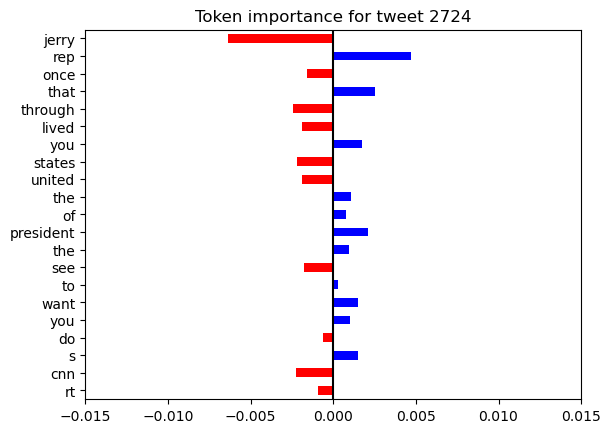

In [ ]:
# Feature importance for a random tweet
i       = np.random.randint(0, tokens.size(0))
figdata = pd.Series(scores[i], index=tokens[i].tolist())
figdata = figdata.rename(index=itos).drop(index='<pad>')
figdata.plot.barh(
    title=f'Token importance for tweet {i}', 
    color=['red' if v < 0 else 'blue' for v in figdata])
plt.xlim(-0.015, 0.015)
plt.axvline(0, color='black')
plt.show()

In [ ]:
# Feature importance across tweets
figdata = pd.DataFrame({'score': scores.view(-1).tolist()}, index=tokens.view(-1).tolist())
figdata = figdata.rename(index=itos).drop(index='<pad>')
figdata = figdata.groupby(figdata.index).mean().sort_values('score', ascending=False)

# Most distinctive Democrat or Republican words
print(f'DEMOCRAT WORDS:\n{figdata.head(10)}\n')
print(f'REPUBLICAN WORDS:\n{figdata.tail(10)}\n')

DEMOCRAT WORDS:
                 score
gunned        0.024748
trum          0.022512
benito        0.020856
gun           0.018506
suing         0.017346
licenses      0.016179
haitian       0.016138
mexicans      0.016051
corporations  0.015878
exxon         0.015739

REPUBLICAN WORDS:
               score
steepest   -0.011595
tooth      -0.011955
fwd        -0.012068
bonuses    -0.012211
abortion   -0.012587
burdens    -0.012829
terrorists -0.013423
preserves  -0.015152
chairman   -0.015922
bent       -0.016565

